# 3. CropHarvest: clean the labels and get satellite data

| Sections | What happens |
|---|---|
| 1. Labels (sections 1–7) | Keep only clear cabbage / carrot / potato **polygon** fields. Data cleaning ambiguous and none labels|
| 2. Pixels (8–9) | Each field 10 m from its edge and pick the pixels left inside. |
| 3. Satellite (10–14) | Find clear-sky days, keep fields whose growing season fits an 8 half-month window, download only those images. |
| 4. Final dataset (15–18) | Build the 64 features, plot them, and test whether a model can tell the crops apart. Final features for Cropharvest exported to the GEE Project Assets |

Data: https://zenodo.org/records/10251170 (download: labels.geojson)

Paper: https://datasets-benchmarks-proceedings.neurips.cc/paper/2021/file/54229abfcfa5649e7003b83dd4755294-Paper-round2.pdf

Repository: https://github.com/nasaharvest/cropharvest

## 1. Setup

Load the libraries.

In [1]:
from pathlib import Path
from contextlib import contextmanager, redirect_stdout
import io
import json
import os
import re
import zipfile
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapefile
from IPython.display import display
from shapely.geometry import Point, shape
from shapely.strtree import STRtree

from crop_pipeline.imagery import bilinear as bilinear_collection
from crop_pipeline.imagery.quality import save_json
from crop_pipeline.sources import cropharvest as cropharvest_source
from crop_pipeline.sources import francecrops as francecrops_workflow
from crop_pipeline.sources import sampling as pilot_sampling

File paths. Notebooks live in `notebooks/`, so we move to the repository root first.

In [2]:
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
ROOT = Path.cwd()

settings_path = ROOT / "settings.local.json"
local_settings = json.loads(settings_path.read_text()) if settings_path.exists() else {}

# Input files
LABELS = ROOT / "data/external/cropharvest/labels.geojson"
COUNTRIES = ROOT / "data/external/cropharvest/ne_50m_admin_0_countries.zip"

# Output files
OUTPUT = ROOT / "outputs/cropharvest_labels/target_crop_labels_screened.csv"
WINDOW_FEATURES_OUTPUT = ROOT / "outputs/cropharvest_labels/cropharvest_window_features.csv"

Working folders: everything CropHarvest produces goes in one `cropharvest/` folder (same layout as FranceCrops inside it). Set `cropharvest_root` in `settings.local.json` to keep it elsewhere.

In [3]:
run_name = bilinear_collection.COLLECTION_NAME
cropharvest_root = Path(local_settings.get("cropharvest_root", "./cropharvest")).expanduser().resolve()
source_handoff_folder = cropharvest_root / "source_handoffs"
imagery_root = cropharvest_root / "imagery" / run_name

earth_engine_project = os.environ.get(
    "EE_PROJECT", local_settings.get("earth_engine_project", "thesis-18"))


def year_folders(year):
    """Folders used for one observation year."""
    return {
        "field": cropharvest_root / "fields" / str(year) / run_name,
        "l2a_reports": cropharvest_root / "l2a" / str(year) / run_name,
        "imagery": imagery_root / str(year),
        "timelines": cropharvest_root / "analysis" / str(year) / run_name / "timelines",
    }

Settings, identical to 02_francecrops_preparation:
- years **2019–2025** (Sentinel-2 surface reflectance is incomplete in earlier years)
- cloud probability **≤ 40**
- a day counts only if **≥ 80%** of the pixels are clear
- **10 m** inward buffer
- target of **500** usable pixels per crop

In [4]:
YEAR_MIN, YEAR_MAX = 2019, 2025
CROP_ORDER = ["cabbage", "carrot", "potato"]
MIN_RELIABLE = 100  # label-count checkpoint only, not an area threshold

sampling_seed = 42
cloud_probability_threshold = 40
minimum_valid_fraction = 0.8
usable_pixels_per_crop = pilot_sampling.USABLE_PIXELS_PER_CROP  # 500
inward_buffer_metres = 10

Check the label file exists and set display options.

In [5]:
if not LABELS.exists():
    raise FileNotFoundError(
        f"Missing {LABELS}. Download the labels first; no automatic downloads occur."
    )

pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})

print("Label file:", LABELS.name, f"({LABELS.stat().st_size / 1e6:.1f} MB)")
print("Country borders available:", COUNTRIES.exists())
print("Working folder:", cropharvest_root)
print("Satellite images:", imagery_root)

Label file: labels.geojson (85.7 MB)
Country borders available: True
Working folder: /Users/almiravelasquez/workspaces/external-crop-data-classification/cropharvest
Satellite images: /Users/almiravelasquez/workspaces/external-crop-data-classification/cropharvest/imagery/bilinear_expanded


Helper: the pipeline prints one line per field group (hundreds of lines like `5493e4… observed summaries reused`). `quiet(...)` sends those lines to a log file and prints a single summary line instead.

In [6]:
@contextmanager
def quiet(step_name):
    """Hide per-field progress lines; save them to logs/<step_name>.log."""
    log_path = cropharvest_root / "logs" / f"{step_name}.log"
    log_path.parent.mkdir(parents=True, exist_ok=True)
    with open(log_path, "w", buffering=1) as log:  # line-buffered: you can follow it live
        with redirect_stdout(log):
            yield
    lines = log_path.read_text().splitlines()
    problems = [line for line in lines if "failed" in line or "error" in line.lower()]
    note = f"{len(problems)} problem lines, e.g. {problems[0]!r}" if problems else "no failures"
    print(f"[{step_name}] {len(lines):,} progress lines saved to logs/{log_path.name} | {note}")

## 2. Load the labels

**Question:** what is in the CropHarvest label file?

Read the GeoJSON file.

In [7]:
with LABELS.open(encoding="utf-8") as f:
    source_geojson = json.load(f)
features = source_geojson["features"]

Turn it into a table: one row per label, with its shape, a unique ID, dates and a lower-case crop name.

In [8]:
lab = pd.DataFrame([f["properties"] for f in features])
lab["geometry"] = [shape(f["geometry"]) if f.get("geometry") else None for f in features]
lab["geom_type"] = [g.geom_type if g is not None else "missing" for g in lab["geometry"]]
lab["uid"] = lab["dataset"].astype(str) + ":" + lab["index"].astype(str)

for col in ["collection_date", "planting_date", "harvest_date", "export_end_date"]:
    lab[col] = pd.to_datetime(lab[col], errors="coerce")
lab["label_norm"] = lab["label"].astype("string").str.strip().str.casefold()

lab_before = lab.copy()  # untouched copy, so later cells can start from the original

Summary of the raw file.

In [9]:
display(pd.DataFrame({
    "metric": ["Labels", "Source datasets", "Distinct crop names", "Labels with a crop name",
               "Polygons", "Points", "Missing collection date"],
    "value": [len(lab), lab.dataset.nunique(), lab.label_norm.nunique(), lab.label_norm.notna().sum(),
              lab.geom_type.eq("Polygon").sum(), lab.geom_type.eq("Point").sum(),
              lab.collection_date.isna().sum()],
}))

,metric,value
0,Labels,113893
1,Source datasets,27
2,Distinct crop names,391
3,Labels with a crop name,46288
4,Polygons,36666
5,Points,77226
6,Missing collection date,0


113,893 labels from 27 datasets with 391 different crop names. 36,666 are polygons (field outlines) and 77,226 are points. No label is missing a date.

## 3. Clean the labels

**Question:** which labels are clearly cabbage, carrot or potato — or clearly another crop, or not a crop?

Every label gets one of five classes: `cabbage`, `carrot`, `potato`, `other_crop`, `non_crop`. Vague names like "vegetables" become `unknown_crop` and are dropped. `chou` counts as cabbage, the same rule as FranceCrops (`CHU`). Small fields are **not** removed here; the 10 m buffer handles that later.

**3a. Keep years 2019–2025.**

In [10]:
lab = lab_before.copy()
original_count = len(lab)

for col in ["collection_date", "export_end_date"]:
    lab[col] = pd.to_datetime(lab[col], errors="coerce")
lab["is_crop"] = pd.to_numeric(lab["is_crop"], errors="coerce")
lab["label_norm"] = (lab["label"].astype("string").str.strip().str.casefold()
                     .replace("", pd.NA))

valid_year = lab["collection_date"].dt.year.between(YEAR_MIN, YEAR_MAX).fillna(False)
lab = lab.loc[valid_year].copy()
print(f"{original_count:,} labels -> {len(lab):,} in {YEAR_MIN}-{YEAR_MAX}")

113,893 labels -> 54,113 in 2019-2025


**3b. Name variants for our three crops** (English and French).

In [11]:
TARGETS = {
    "potato": {
        "potato": "",
        "potatoes": "",
        "pomme de terre de consommation": "table potato (FR)",
        "pomme de terre féculière": "starch potato (FR)",
    },
    "carrot": {
        "carrot": "",
        "carrots": "",
        "carotte": "carrot (FR)",
    },
    "cabbage": {
        "cabbage": "",
        "chou": "cabbage (FR); FranceCrops CHU",
    },
}

**3c. Give each label its crop name** (empty if it is not one of the three).

In [12]:
REVIEW_LABELS = {}

ALIAS_TO_CROP = {alias: crop for crop, variants in TARGETS.items() for alias in variants}
ALIAS_NOTES = {alias: note for variants in TARGETS.values() for alias, note in variants.items()}

lab["crop"] = lab["label_norm"].map(ALIAS_TO_CROP).astype("string")
lab["crop_note"] = lab["label_norm"].map(ALIAS_NOTES).fillna("")

**3d. Flag mixed or intercropped labels.** Two crops in one field give a mixed satellite signal.

In [13]:
MIXED_WORDS = (
    r"\bmix(?:ed|ture|ing)?\b|"
    r"\binter[\s-]?crop\w*\b|"
    r"\bm[ée]lange\w*\b|"
    r"\bassociation\b|"
    r"\bpolyculture\b|"
    r"\bassoc\w*\b|"
    r"\bwith other crops\b"
)
MULTI_CROP = {
    "café / cacao",
    "cauliflower and brocoli",
    "canola/rapeseed (with other crops)",
}

lab["mixed_label"] = (
    lab["label_norm"].str.contains(MIXED_WORDS, regex=True, na=False)
    | lab["label_norm"].isin(MULTI_CROP)
).fillna(False)
print("Mixed labels:", int(lab["mixed_label"].sum()))

Mixed labels: 483


**3e. List vague crop names.** These could hide a cabbage, carrot or potato field, so they cannot be used as `other_crop`.

In [14]:
GENERIC_CROPS = {
    "annual crop",
    "vegetables",
    "vegetables (undiff)",
    "leafy or stem vegetable",
    "root",
    "root crops",
    "root, bulb or tuberous vegetable",
    "root/tuber crop with high starch or inulin content",
    "other",
    "other agriculture (undiff)",
    "market gardening",
    "autre légume ou fruit annuel",
    "légume sous abri",
} | set(REVIEW_LABELS)

**3f. Give every label one of the five classes.**

In [15]:
# Start everything as unknown.
lab["model_class"] = pd.Series("unknown_crop", index=lab.index, dtype="string")

# Not a crop (kept even without a name).
lab.loc[lab["is_crop"].eq(0), "model_class"] = "non_crop"

# One of our three crops.
target_mask = lab["is_crop"].eq(1) & lab["crop"].notna()
lab.loc[target_mask, "model_class"] = lab.loc[target_mask, "crop"]

# A clearly named crop that is not one of ours.
other_mask = (lab["is_crop"].eq(1) & lab["label_norm"].notna()
              & lab["crop"].isna() & ~lab["label_norm"].isin(GENERIC_CROPS))
lab.loc[other_mask, "model_class"] = "other_crop"

display(lab["model_class"].value_counts().rename("labels").to_frame())

,labels
model_class,
unknown_crop,20823
other_crop,17571
non_crop,14546
potato,580
carrot,380
cabbage,213


**3g. Find conflicts:** the exact same field shape, same season, but two different crop names.

In [16]:
lab["geom_wkb"] = [g.wkb_hex if g is not None and not g.is_empty else None for g in lab.geometry]

identity = lab["label_norm"].copy()
identity.loc[lab["is_crop"].eq(0)] = "non_crop"

check = pd.DataFrame({"geom": lab["geom_wkb"], "season": lab["export_end_date"],
                      "identity": identity}, index=lab.index)
valid = (check["geom"].notna() & check["season"].notna()
         & check["identity"].notna() & ~lab["mixed_label"])

names_per_field = check.loc[valid].groupby(["geom", "season"])["identity"].nunique()
conflict_keys = set(names_per_field[names_per_field > 1].index)
lab["season_conflict"] = [(geo, season) in conflict_keys
                          for geo, season in zip(lab["geom_wkb"], lab["export_end_date"])]
print("Labels in a conflict:", int(lab["season_conflict"].sum()))

Labels in a conflict: 138


**3h. Keep only the clean labels.**

In [17]:
keep = (~lab["mixed_label"]
        & ~lab["season_conflict"]
        & lab["model_class"].ne("unknown_crop")
        & lab["export_end_date"].notna()
        & lab["geom_wkb"].notna())
lab_clean = lab.loc[keep].copy()
print(f"Clean labels: {len(lab_clean):,}")

Clean labels: 32,668


**3i. How many labels survived each step?**

In [18]:
stages = [
    ("Original dataset", original_count),
    ("After year filter", len(lab)),
    ("After mixed-label filter", int((~lab["mixed_label"]).sum())),
    ("After conflict filter", int((~lab["mixed_label"] & ~lab["season_conflict"]).sum())),
    ("After geometry/date check", int((~lab["mixed_label"] & ~lab["season_conflict"]
                                       & lab["geom_wkb"].notna()
                                       & lab["export_end_date"].notna()).sum())),
    ("Final five-class dataset", len(lab_clean)),
]
filter_summary = pd.DataFrame(stages, columns=["Stage", "Records"])
filter_summary["Removed"] = (-filter_summary["Records"].diff()).fillna(0).astype(int)
filter_summary["Kept (%)"] = (filter_summary["Records"] / original_count * 100).round(2)
display(filter_summary)

,Stage,Records,Removed,Kept (%)
0,Original dataset,113893,0,100.00
1,After year filter,54113,59780,47.51
2,After mixed-label filter,53630,483,47.09
3,After conflict filter,53492,138,46.97
4,After geometry/date check,53491,1,46.97
5,Final five-class dataset,32668,20823,28.68


Classes before and after cleaning.

In [19]:
class_comparison = pd.concat([
    lab["model_class"].value_counts().rename("Before"),
    lab_clean["model_class"].value_counts().rename("After"),
], axis=1).fillna(0).astype(int)
class_comparison["Removed"] = class_comparison["Before"] - class_comparison["After"]
display(class_comparison)

,Before,After,Removed
model_class,,,
unknown_crop,20823,0,20823
other_crop,17571,16950,621
non_crop,14546,14545,1
potato,580,580,0
carrot,380,380,0
cabbage,213,213,0


**Result:** 113,893 labels → 54,113 in 2019–2025 → **32,668 clean labels**. Most of the drop is the year filter and the 20,823 vague names. Our crops: **potato 580, carrot 380, cabbage 213** (plus 16,950 other crop and 14,545 non-crop).

## 4. Keep only field outlines (polygons)

**Question:** how many of our crop labels are polygons? A point has no area, so it cannot be shrunk by 10 m and is dropped.

Take the three target crops and note each label's shape type.

In [20]:
tg = lab_clean.loc[lab_clean["crop"].isin(CROP_ORDER)].copy()
tg["geom_type"] = tg["geometry"].apply(lambda g: getattr(g, "geom_type", None))

display(tg.groupby("crop").agg(
    labels=("crop", "size"),
    sources=("dataset", "nunique"),
    polygons=("geom_type", lambda s: int(s.isin(["Polygon", "MultiPolygon"]).sum())),
    points=("geom_type", lambda s: int(s.isin(["Point", "MultiPoint"]).sum())),
    reserved_test=("is_test", lambda s: int(s.eq(True).sum())),
).reindex(CROP_ORDER, fill_value=0))

,labels,sources,polygons,points,reserved_test
crop,,,,,
cabbage,213,6,176,37,0
carrot,380,4,380,0,0
potato,580,4,577,3,0


Which sources the dropped points come from.

In [21]:
is_polygon = tg["geom_type"].isin(["Polygon", "MultiPolygon"])
display(pd.crosstab(tg.loc[~is_polygon, "crop"], tg.loc[~is_polygon, "dataset"])
        .reindex(CROP_ORDER, fill_value=0))

dataset,canada,croplands
crop,,
cabbage,37,0
carrot,0,0
potato,0,3


Drop the points.

In [22]:
tg = tg.loc[is_polygon].copy()
print(f"Polygon labels kept: {len(tg):,}")

Polygon labels kept: 1,133


**Result:** **1,133 polygons** kept (cabbage 176, carrot 380, potato 577). 40 points dropped (37 cabbage from Canada, 3 potato from croplands).

## 5. Where are the fields?

**Question:** which countries do the labels come from? If each crop comes mostly from one country, a model might learn the country instead of the crop.

Load country borders and make a lookup: (lon, lat) → country name.

In [23]:
if COUNTRIES.exists():
    with zipfile.ZipFile(COUNTRIES) as archive:
        shp = io.BytesIO(archive.read("ne_50m_admin_0_countries.shp"))
        dbf = io.BytesIO(archive.read("ne_50m_admin_0_countries.dbf"))
        reader = shapefile.Reader(shp=shp, dbf=dbf)
        country_shapes = [(shape(record.shape.__geo_interface__), record.record["NAME"])
                          for record in reader.iterShapeRecords()]

    polygons = [geom for geom, _ in country_shapes]
    tree = STRtree(polygons)
    geom_index = {id(g): i for i, g in enumerate(polygons)}

    def polygon_index(candidate):
        # Shapely 2 returns an integer index; Shapely 1 returns the geometry itself.
        if isinstance(candidate, (int, np.integer)):
            return int(candidate)
        j = geom_index.get(id(candidate))
        if j is not None:
            return j
        return next(i for i, g in enumerate(polygons) if g.equals(candidate))

    def country_of(lon, lat):
        point = Point(float(lon), float(lat))
        for item in tree.query(point):
            j = polygon_index(item)
            if polygons[j].contains(point):
                return country_shapes[j][1]
        return country_shapes[polygon_index(tree.nearest(point))][1]  # nearest if at sea

Give every label a country (Réunion and Martinique are named by their dataset) and a 1° grid cell.

In [24]:
if COUNTRIES.exists():
    TERRITORY = {"reunion-france": "Réunion (FR)", "martinique-france": "Martinique (FR)"}
    tg["country"] = [TERRITORY.get(dataset) or country_of(lon, lat)
                     for dataset, lon, lat in zip(tg.dataset, tg.lon, tg.lat)]
else:
    tg["country"] = tg["dataset"].astype("string")
    print("Country borders ZIP not found: dataset names used instead.")

tg["cell_1deg"] = (np.floor(tg.lat).astype(int).astype(str) + "," +
                   np.floor(tg.lon).astype(int).astype(str))

Labels per country and crop.

crop,cabbage,carrot,potato,total
country,,,,
Madagascar,70,342,273,685
France,19,30,200,249
Réunion (FR),7,3,101,111
Senegal,62,0,3,65
Martinique (FR),17,5,0,22
Kenya,1,0,0,1


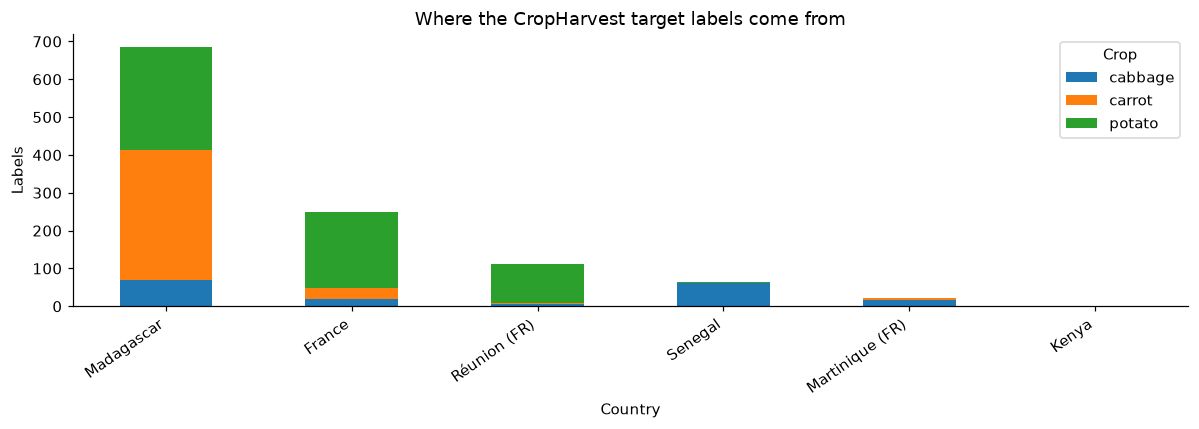

In [25]:
country_crop = pd.crosstab(tg.country, tg.crop).reindex(columns=CROP_ORDER, fill_value=0)
display(country_crop.assign(total=country_crop.sum(axis=1)).sort_values("total", ascending=False))

ax = country_crop.loc[country_crop.sum(axis=1).sort_values(ascending=False).index].plot(
    kind="bar", stacked=True, figsize=(11, 4))
ax.set(title="Where the CropHarvest target labels come from", xlabel="Country",
       ylabel="Labels")
ax.legend(title="Crop")
plt.xticks(rotation=35, ha="right")
plt.tight_layout(); plt.show()

How often do two of our crops grow in the same 1° area?

In [26]:
shared = (tg.groupby("cell_1deg").crop.nunique() >= 2).sum()
print(f"1° cells with at least two target crops: {shared}")

1° cells with at least two target crops: 10


**Result:** Madagascar 685 labels (mostly carrot and potato), France 249 (mostly potato), Réunion 111, Senegal 65 (almost all cabbage), Martinique 22, Kenya 1. Only **10** one-degree cells hold two or more of our crops, so crop and place are strongly linked.

## 6. Field size and label source

**Question:** how trustworthy is each source, and how big are the fields?

How each source collected its labels, and a trust grade (a judgement, not a check of the crop).

In [27]:
METHOD = {
    "jecam": ("in-situ field survey (JECAM sites)", "high"),
    "canada": ("AAFC ground-truth points (Annual Crop Inventory)", "high"),
    "ile-de-france": ("farmer parcel declarations (French RPG)", "high"),
    "reunion-france": ("farmer parcel declarations (French RPG)", "high"),
    "martinique-france": ("farmer parcel declarations (French RPG)", "high"),
    "kenya": ("field survey", "high"),
    "croplands": ("GFSAD / croplands reference samples (field + image interpretation)", "medium"),
}

Field area (approximate, from degrees), broken shapes, and duplicates.

In [28]:
g = tg.copy()
meters_per_degree = 111_320.0
g["area_ha"] = [geom.area * meters_per_degree**2 * np.cos(np.radians(lat)) / 1e4
                if kind == "Polygon" else np.nan
                for geom, lat, kind in zip(g.geometry, g.lat, g.geom_type)]
g["invalid_geom"] = [kind == "Polygon" and not geom.is_valid
                     for geom, kind in zip(g.geometry, g.geom_type)]

# Same shape twice in one source / in several sources.
g["dup_in_source"] = g.duplicated(["dataset", "geom_wkb"], keep=False)
dup_source_count = lab.groupby("geom_wkb").dataset.nunique()
g["dup_across_sources"] = g.geom_wkb.map(dup_source_count).gt(1)

# Crop group in the file differs from what we expect.
expected_group = {"potato": "root_tuber", "carrot": "vegetables_melons", "cabbage": "vegetables_melons"}
g["group_mismatch"] = g.classification_label.ne(g.crop.map(expected_group))

# Same field labelled differently in another season.
other_season_count = lab.dropna(subset=["label_norm"]).groupby("geom_wkb").label_norm.nunique()
g["relabelled_other_season"] = g.geom_wkb.map(other_season_count).gt(1)

Season dating: does the label have a planting date, an in-season observation, only a year, or dates that do not fit?

In [29]:
g["placeholder_date"] = g.collection_date.dt.month.eq(1) & g.collection_date.dt.day.eq(1)
start = g.export_end_date - pd.DateOffset(months=12)
inside = g.collection_date.between(start, g.export_end_date)
same_year = g.collection_date.dt.year.eq(start.dt.year)

g["season_class"] = np.select(
    [g.planting_date.notna(), inside & ~g.placeholder_date,
     g.placeholder_date & (inside | same_year)],
    ["planting / harvest dated", "in-season observation", "season-year only"],
    default="inconsistent")
g["season_year"] = start.dt.year

Flag sources whose planting dates are nearly all the same day (likely filler dates), and attach the source grade.

In [30]:
planting_days_by_source = (g.groupby("dataset").planting_date
                           .transform(lambda s: s.dropna().dt.strftime("%m-%d").nunique()))
g["planting_date_placeholder_suspected"] = g.planting_date.notna() & planting_days_by_source.le(2)

g["source_method"] = g.dataset.map(lambda x: METHOD.get(x, ("unknown", "unknown"))[0])
g["source_grade"] = g.dataset.map(lambda x: METHOD.get(x, ("unknown", "unknown"))[1])

One row per crop and source.

In [31]:
display(g.groupby(["crop", "dataset"]).agg(
    labels=("uid", "size"),
    source_grade=("source_grade", "first"),
    median_area_ha=("area_ha", "median"),
    year_only=("season_class", lambda s: int(s.eq("season-year only").sum())),
    planting_date_present=("planting_date", lambda s: int(s.notna().sum())),
    suspected_placeholder=("planting_date_placeholder_suspected", "sum"),
))

labels source_grade  median_area_ha  year_only  \
crop    dataset                                                             
cabbage ile-de-france          19         high        0.535117         19   
        jecam                 132         high        0.081934          0   
        kenya                   1         high        0.022843          0   
        martinique-france      17         high        0.343273         17   
        reunion-france          7         high        0.150441          7   
carrot  ile-de-france          30         high        0.843944         30   
        jecam                 342         high        0.048337          0   
        martinique-france       5         high        0.315416          5   
        reunion-france          3         high        0.084889          3   
potato  ile-de-france         200         high        5.069368        200   
        jecam                 276         high        0.065409          0   
        reunion-france        101         high        0.573935        101   

                           planting_date_present  suspected_placeholder  
crop    dataset                                                          
cabbage ile-de-france                          0                      0  
        jecam                                132                    132  
        kenya                                  1                      1  
        martinique-france                      0                      0  
        reunion-france                         0                      0  
carrot  ile-de-france                          0                      0  
        jecam                                342                    342  
        martinique-france                      0                      0  
        reunion-france                         0                      0  
potato  ile-de-france                          0                      0  
        jecam                                276                    276  
        reunion-france                         0                      0

**Result:** every source used here is rated high. JECAM (Madagascar) gives most of the fields, but they are tiny. Some planting dates look like filler dates — they are flagged, not removed.

## 7. Final label check and save

**Question:** does each label pass the source checks? A label passes if its source is rated high, its shape is valid, the same shape is not in another source, and its dates make sense.

Mark each label as passed, or give the first reason it failed.

In [32]:
g["reliable"] = (g.source_grade.eq("high") & ~g.invalid_geom
                 & ~g.dup_across_sources & g.season_class.ne("inconsistent"))

checks = [
    ("Source not high grade", ~g.source_grade.eq("high")),
    ("Invalid polygon", g.invalid_geom),
    ("Duplicate across sources", g.dup_across_sources),
    ("Season inconsistent", g.season_class.eq("inconsistent")),
]
g["fail_reason"] = "passed"
for reason, mask in reversed(checks):  # reversed, so the FIRST failing check wins
    g.loc[mask.fillna(False), "fail_reason"] = reason
assert g.reliable.equals(g.fail_reason.eq("passed")), "Check screening and exclusion reasons"

Passed vs. excluded per crop.

,candidates,passed,sources,excluded,passed_pct,enough_for_pilot
crop,,,,,,
cabbage,176,176,5,0,100.0,True
carrot,380,380,4,0,100.0,True
potato,577,577,3,0,100.0,True


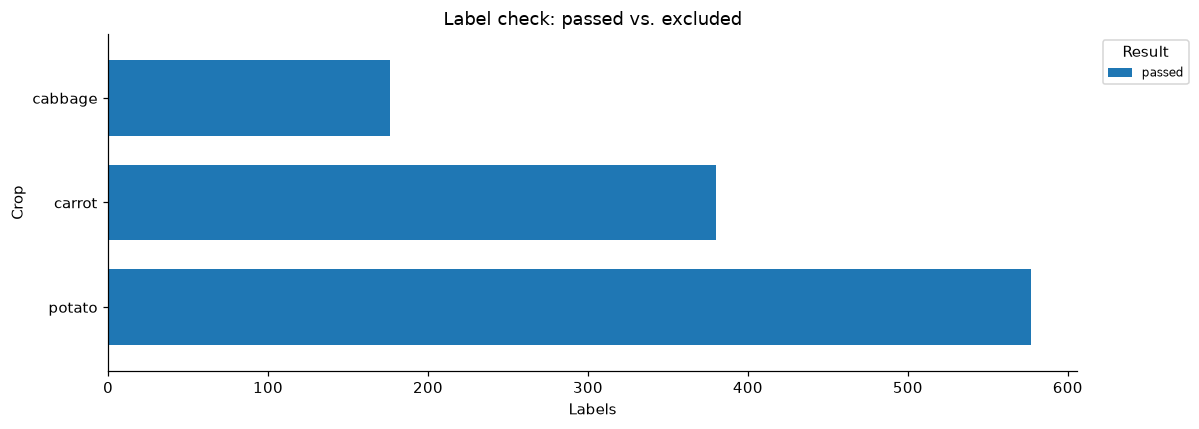

In [33]:
verdict = g.groupby("crop").agg(candidates=("uid", "size"),
                                passed=("reliable", "sum"),
                                sources=("dataset", "nunique"))
verdict["excluded"] = verdict.candidates - verdict.passed
verdict["passed_pct"] = (verdict.passed / verdict.candidates * 100).round(1)
verdict["enough_for_pilot"] = verdict.passed >= MIN_RELIABLE
verdict = verdict.reindex(CROP_ORDER)
display(verdict)

funnel = pd.crosstab(g.crop, g.fail_reason).reindex(index=verdict.index, fill_value=0)
reason_order = ["passed"] + [name for name, _ in checks if name in funnel]
funnel = funnel.reindex(columns=reason_order, fill_value=0)
ax = funnel.plot.barh(stacked=True, figsize=(11, 4), width=0.72)
ax.set(xlabel="Labels", ylabel="Crop", title="Label check: passed vs. excluded")
ax.invert_yaxis()
ax.legend(title="Result", fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

Save all labels (passed and excluded) with the `reliable` column as the verdict.

In [34]:
original_columns = [col for col in g.columns if col not in
                    {"geometry", "geom_wkb", "source_method", "source_grade",
                     "planting_date_placeholder_suspected", "fail_reason"}]
to_export = g[original_columns]
OUTPUT.parent.mkdir(parents=True, exist_ok=True)
to_export.to_csv(OUTPUT, index=False)
print(f"Saved {len(to_export):,} labels to {OUTPUT.name}")

Saved 1,133 labels to target_crop_labels_screened.csv


**Result:** all **1,133** labels pass (100% for each crop). Saved to `target_crop_labels_screened.csv`.

**Limitations:**
- some dates may be filler dates;
- a label says which crop was reported, not which crop was there in every cycle;
- nearby fields from one survey look alike, so train/test splits must be by field (`partition_group`).

---
# Part 2 — Preparing the pixels

## 8. Shrink fields by 10 m and count the pixels inside

**Question:** after shrinking each field 10 m from its edge, how many clean 10 m pixels are left — enough for 500 per crop? This is checked **before** any Earth Engine call.

Turn each passed, non-test label into a field outline (same format as FranceCrops).

In [35]:
from crop_pipeline.windows.seasons import file_sha256

labels_revision = "labels.geojson sha256:" + file_sha256(LABELS)  # fingerprint of the input file
eligible = g.loc[g["reliable"].eq(True) & ~g["is_test"].eq(True)].copy()
eligible["year"] = eligible["collection_date"].dt.year.astype(int)

features, footprint_exclusions = [], []
for uid, geometry, crop, year, country, dataset in zip(
        eligible["uid"], eligible["geometry"], eligible["crop"], eligible["year"],
        eligible["country"], eligible["dataset"]):
    try:
        features.append(cropharvest_source.parcel_feature(
            uid, geometry, crop, year, country, dataset, labels_revision))
    except ValueError as error:
        footprint_exclusions.append({"uid": uid, "reason": str(error)})

Shrink by 10 m, list the pixels left inside each field, and drop fields with none.

In [36]:
catalog = francecrops_workflow.build_parcel_catalog(features, sampling_seed, inward_buffer_metres)
interior = pd.DataFrame(cropharvest_source.interior_capacity(features, catalog))
interior["has_interior_pixel"] = interior["interior_pixels"].gt(0)
features = [f for f, keep in zip(features, interior["has_interior_pixel"]) if keep]

print(f"Fields: {len(interior):,} | invalid outlines: {len(footprint_exclusions)} | "
      f"with a pixel left after the {inward_buffer_metres} m buffer: {len(features):,}")

Fields: 1,133 | invalid outlines: 0 | with a pixel left after the 10 m buffer: 517


Fields and interior pixels per crop and source.

In [37]:
display(interior.groupby(["crop", "source_dataset"]).agg(
    fields=("parcel_id", "size"),
    fields_with_interior=("has_interior_pixel", "sum"),
    interior_pixels=("interior_pixels", "sum"),
    capped_pixels=("capped_pixels", "sum"),  # at most 100 per field group
).reindex(CROP_ORDER, level=0))

fields  fields_with_interior  interior_pixels  \
crop    source_dataset                                                     
cabbage ile-de-france          19                    14              811   
        jecam                 132                    56              707   
        kenya                   1                     0                0   
        martinique-france      17                    16              527   
        reunion-france          7                     5               67   
carrot  ile-de-france          30                    27             1520   
        jecam                 342                    57              166   
        martinique-france       5                     3               75   
        reunion-france          3                     2              101   
potato  ile-de-france         200                   169            15628   
        jecam                 276                    73              299   
        reunion-france        101                    95             3852   

                           capped_pixels  
crop    source_dataset                    
cabbage ile-de-france                811  
        jecam                        707  
        kenya                          0  
        martinique-france            527  
        reunion-france                67  
carrot  ile-de-france               1520  
        jecam                        166  
        martinique-france             75  
        reunion-france               101  
potato  ile-de-france              15628  
        jecam                        299  
        reunion-france              3852

Capacity check: is there enough per crop?

In [38]:
capacity = pd.DataFrame(bilinear_collection.capacity_report(
    catalog, bilinear_collection.CANDIDATE_BUDGETS)).set_index("crop").reindex(CROP_ORDER)
capacity["usable_target"] = usable_pixels_per_crop
capacity["pipeline_minimum_candidates"] = 3000
capacity["meets_pipeline_minimum"] = capacity["available_capped_pixels"].gt(3000)
capacity["can_reach_usable_target"] = capacity["available_capped_pixels"].ge(usable_pixels_per_crop)
display(capacity)

,requested_candidates,available_unique_pixels,available_capped_pixels,available_groups,shortfall,usable_target,pipeline_minimum_candidates,meets_pipeline_minimum,can_reach_usable_target
crop,,,,,,,,,
cabbage,7000,2112,2112,91,4888,500,3000,False,True
carrot,3400,1862,1862,89,1538,500,3000,False,True
potato,10000,19779,19779,337,0,500,3000,True,True


Save the check.

In [39]:
save_json(cropharvest_root / "capacity_check.json", {
    "inward_buffer_metres": inward_buffer_metres,
    "capacity": capacity.reset_index().to_dict("records"),
    "fields": interior.to_dict("records"),
    "footprint_exclusions": footprint_exclusions,
})
if not len(catalog):
    raise ValueError("No interior pixels remain after the inward buffer.")

**Result:** only **517 of 1,133** fields still have a pixel inside after the buffer (many JECAM fields are too small). Unique interior pixels: **cabbage 2,112, carrot 1,862, potato 19,779** — all above 500, but below the pipeline's 3,000 minimum.

## 9. Pick the pixels for each year

**Question:** which pixels do we send to Earth Engine?

Earth Engine is queried one year at a time, so pixels are picked per year. Because CropHarvest is small, **every** interior pixel is taken (at most 100 per field group, no pixel twice). Each pixel keeps its field ID (`partition_group`) so later train/test splits are by field.

In [40]:
year_inputs = {}
for year in sorted({feature["properties"]["year"] for feature in features}):
    folders = year_folders(year)

    # Pixels of this year only; partition_group looks like "...|country|year|..."
    year_catalog = [row for row in catalog if row["partition_group"].split("|")[2] == str(year)]
    regions, sampling_summary, budgets = cropharvest_source.sample_year_candidates(
        year_catalog, folders["field"], sampling_seed)

    # Save this year's field outlines and where they came from.
    year_features = [f for f in features if f["properties"]["year"] == year]
    save_json(folders["field"] / "cropharvest_parcels.geojson",
              {"type": "FeatureCollection", "features": year_features})
    save_json(folders["field"] / "source_provenance.json", {
        "dataset": cropharvest_source.DATASET_NAME,
        "revision": labels_revision,
        "year": year,
        "label_aliases": TARGETS,
        "label_status": "reported",
        "geometry": "polygons only",
        "inward_buffer_metres": inward_buffer_metres,
        "source_datasets": sorted({f["properties"]["source_dataset"] for f in year_features}),
    })

    year_inputs[year] = {**folders, "regions": regions, "summary": sampling_summary,
                         "budgets": budgets}

Pixels and field groups picked per year (before any cloud or timing filter).

In [41]:
display(pd.DataFrame([
    {"year": year, "crop": crop, "candidate_pixels": count,
     "field_groups": inputs["summary"]["groups_per_crop"].get(crop, 0)}
    for year, inputs in year_inputs.items()
    for crop, count in inputs["summary"]["candidate_pixels_per_crop"].items()
]).pivot_table(index="crop", columns="year", values=["candidate_pixels", "field_groups"],
               fill_value=0).reindex(CROP_ORDER))

candidate_pixels        field_groups      
year                2019   2021         2019  2021
crop                                              
cabbage           1419.0  693.0         42.0  49.0
carrot            1862.0    0.0         89.0   0.0
potato           19749.0   30.0        334.0   3.0

**Result:** labels fall in two years. **2019:** cabbage 1,419, carrot 1,862, potato 19,749 pixels. **2021:** cabbage 693, potato 30, no carrot.

---
# Part 3 — Satellite imagery

## 10. Connect to Earth Engine

Same image rules as notebook 02:
- Sentinel-2 surface reflectance (`COPERNICUS/S2_SR_HARMONIZED`);
- clouds, shadows and snow masked using the scene classification **and** cloud probability < 40 (an image with no cloud-probability match is skipped, never assumed clear);
- the 20 m bands B5 and B11 are resampled to 10 m (bilinear) before combining images.

Log in once by hand with `ee.Authenticate()`; no keys are stored here.

Some Python installs have no certificate list; point to `certifi`'s.

In [42]:
import ssl
import certifi

os.environ.setdefault("SSL_CERT_FILE", certifi.where())
print("Trusted CA certificates:", ssl.create_default_context().cert_store_stats()["x509_ca"])

Trusted CA certificates: 121


Start Earth Engine and make one image retriever per year.

In [43]:
import ee
from crop_pipeline.imagery.retrieval import REQUEST_VERSION, SatelliteRetriever

ee.Initialize(project=earth_engine_project)
retrievers = {
    year: SatelliteRetriever(ee, year, inputs["imagery"], inputs["l2a_reports"],
                             cloud_probability_threshold)
    for year, inputs in year_inputs.items()
}
print("Earth Engine project:", earth_engine_project, "| request version:", REQUEST_VERSION)

Earth Engine project: thesis-18 | request version: 4


The slow work runs as **batch tasks** on Earth Engine's servers, so VS Code does not have to stay open. Each task handles many field groups. Its result goes to a temporary asset under `cropharvest/tmp`, is saved into the usual files, checked, and then the temporary asset is deleted. `batch/tasks.json` remembers every task, so finished or running work is never submitted twice.

In [44]:
from crop_pipeline.imagery import batch_export

ASSET_ROOT = f"projects/{earth_engine_project}/assets/cropharvest"
TEMP_ASSETS = f"{ASSET_ROOT}/tmp"                        # deleted once saved locally
BATCH_LEDGER = cropharvest_root / "batch" / "tasks.json"  # every task submitted


def show_tasks(report):
    """One row per task, with the EECU-seconds it used."""
    table = pd.DataFrame(report)
    if table.empty:
        print("No tasks of this kind yet.")
        return
    display(table)
    print(f"EECU-seconds used: {table['eecu_seconds'].sum():,.4f}")

## 11. Which days are clear?

**Question:** on which days can each field be seen clearly?

For each field group we list every Sentinel-2 image of the year, then compute the daily greenness (NDVI), leaf (NDRE) and moisture (NDMI) indices on the picked pixels. A day counts only if **≥ 80%** of the pixels are cloud-free. Nothing is downloaded yet — these are small tables.

**11a.** List the images covering each field group.

In [46]:
for year, inputs in year_inputs.items():
    plans, inventory_errors = retrievers[year].build_plans(inputs["regions"])
    inputs["plans"] = plans
    print(f"{year}: {len(plans):,} field groups | errors: {len(inventory_errors)}")

2019: 465 field groups | errors: 0
2021: 52 field groups | errors: 0


**11b. Submit** the daily-index tasks. This returns right away; Earth Engine keeps working with VS Code closed. Field groups that already have a saved result, or a task still running, are skipped.

In [47]:
for year, inputs in year_inputs.items():
    submitted = batch_export.submit_daily(
        ee, retrievers[year], inputs["plans"], inputs["timelines"],
        BATCH_LEDGER, TEMP_ASSETS, year)
    print(year, submitted)

2019 {'regions_needing_work': 0, 'tasks_submitted': 0, 'already_running': 0}
2021 {'regions_needing_work': 0, 'tasks_submitted': 0, 'already_running': 0}


**11c. Collect** the results — run this any time later. Each finished task is saved into the same files as before (`timelines/observed_checkpoints/…json`), its dates are checked against the plan, and its temporary asset is deleted.

In [48]:
plans_by_id = {plan["fragment_id"]: plan
               for inputs in year_inputs.values() for plan in inputs["plans"]}


def save_daily(entry, table):
    """Write one checkpoint per field group, exactly like the live code."""
    region_ids = [item.split("|")[1] for item in entry["items"]]
    written = batch_export.write_daily_checkpoints(
        plans_by_id, region_ids, table, year_inputs[entry["year"]]["timelines"],
        minimum_valid_fraction)
    return f"{written} field groups saved"


show_tasks(batch_export.collect(ee, earth_engine_project, BATCH_LEDGER, {"daily": save_daily}))
print(batch_export.remove_temp_folder(ee, BATCH_LEDGER, TEMP_ASSETS))


No tasks of this kind yet.
temporary folder removed


Combine the saved results into each year's timeline files (no Earth Engine requests). If any field group is still missing, this stops — run 11b and 11c again later.

In [49]:
from crop_pipeline.imagery import timelines as observed_timelines

for year, inputs in year_inputs.items():
    missing = batch_export.missing_daily_checkpoints(inputs["plans"], inputs["timelines"])
    if missing:
        raise RuntimeError(f"{year}: {len(missing)} field groups not saved yet — "
                           "tasks still running or not submitted. Run 11b / 11c again later.")
    with quiet(f"daily_summaries_{year}"):  # every field group is reused from its checkpoint
        inputs["observed"] = observed_timelines.retrieve_observed_timelines(
            inputs["plans"], retrievers[year].mask_acquisition, ee,
            inputs["timelines"], minimum_valid_fraction)

[daily_summaries_2019] 465 progress lines saved to logs/daily_summaries_2019.log | no failures
[daily_summaries_2021] 52 progress lines saved to logs/daily_summaries_2021.log | no failures


**11d.** How many field-days were clear enough?

In [50]:
daily_summary = pd.DataFrame([
    {"year": year,
     "field_groups": len(inputs["plans"]),
     "field_days": len(inputs["observed"]),
     "clear_field_days": int(sum(row["eligible"] for row in inputs["observed"]))}
    for year, inputs in year_inputs.items()
])
daily_summary["clear_%"] = (daily_summary["clear_field_days"]
                            / daily_summary["field_days"].replace(0, np.nan) * 100).round(1)
display(daily_summary)

,year,field_groups,field_days,clear_field_days,clear_%
0,2019,465,46949,21204,45.2
1,2021,52,3796,2176,57.3


**Result:** **2019:** 465 field groups, 46,949 field-days, 21,204 clear (about 45%). **2021:** 52 field groups, 3,796 field-days, 2,176 clear.

## 12. Timing check: does a growing season fit?

**Question:** does each field show a growing cycle that fits in **8 half-months** inside the year?

The rule is the same as FranceCrops (`select_timing_plans`). A season that needs images from the year before or after is **logged, not downloaded**, because notebook 03 reads one year per source.

Run the check per year (writes `timing_first/download_selection.json`).

In [51]:
for year, inputs in year_inputs.items():
    gate_folder = inputs["l2a_reports"] / "timing_first"
    inputs["selected_plans"] = (bilinear_collection.select_timing_plans(
        inputs["plans"], inputs["observed"], gate_folder) if inputs["plans"] else [])

One row per field group: did it pass, and if not, why?

In [52]:
gate_rows = []
for year, inputs in year_inputs.items():
    selection_path = inputs["l2a_reports"] / "timing_first" / "download_selection.json"
    selection = json.loads(selection_path.read_text())
    pending = {row["region_id"]: row for row in selection["pending"]}  # the ones that failed
    selected_ids = {plan["fragment_id"] for plan in inputs["selected_plans"]}

    for plan in inputs["plans"]:
        properties = plan["fragment"]["properties"]
        problem = pending.get(plan["fragment_id"], {})
        gate_rows.append({
            "year": year, "crop": properties["crop"], "region_id": plan["fragment_id"],
            "sampled_pixels": properties["selected_pixels"],
            "qualified": plan["fragment_id"] in selected_ids,
            "adjacent_year_needed": problem.get("reason") == "adjacent_year_imagery_required",
            "no_qualified_window": problem.get("reason") == "no_timing_qualified_window",
        })
gate = pd.DataFrame(gate_rows)

Summary per year and crop.

In [53]:
display(gate.groupby(["year", "crop"]).agg(
    field_groups=("region_id", "size"),
    passed=("qualified", "sum"),
    needs_other_year=("adjacent_year_needed", "sum"),
    no_fitting_window=("no_qualified_window", "sum"),
    pixels=("sampled_pixels", "sum"),
    pixels_passed=("sampled_pixels", lambda s: int(s[gate.loc[s.index, "qualified"]].sum())),
))

field_groups  passed  needs_other_year  no_fitting_window  \
year crop                                                                 
2019 cabbage            42      18                 4                 22   
     carrot             89      53                18                 30   
     potato            334      69                27                247   
2021 cabbage            49      14                 2                 33   
     potato              3       0                 0                  3   

              pixels  pixels_passed  
year crop                            
2019 cabbage    1419            317  
     carrot     1862            805  
     potato    19749           1434  
2021 cabbage     693            158  
     potato       30              0

**Result:** pixels that passed — **2019:** cabbage 317, carrot 805, potato 1,434; **2021:** cabbage 158, potato 0. **51** field groups needed the next/previous year's images (cabbage 6, carrot 18, potato 27); most others had no clear growing rise.

## 13. Download the images

Only the windows that passed are downloaded. Each file is the **median of one half-month** (bands B2, B3, B4, B5, B8, B11 and a clear-day count). The images are built by batch tasks (13a), collected later (13b) and checked (13c). Saved images are reused on re-runs; failed tasks are resubmitted.

**13a. Submit** the image tasks. Returns right away. Half-month images already saved and checked, or in a running task, are skipped.

In [54]:
for year, inputs in year_inputs.items():
    if inputs["selected_plans"]:
        submitted = batch_export.submit_composites(
            ee, retrievers[year], inputs["selected_plans"], BATCH_LEDGER, TEMP_ASSETS, year)
        print(year, submitted)

2019 {'composites_needing_work': 0, 'tasks_submitted': 0}
2021 {'composites_needing_work': 0, 'tasks_submitted': 0}


**13b. Collect** the images — run any time later. Each half-month GeoTIFF is rebuilt on its exact grid, checked like a download, recorded in the same manifest, and its temporary asset deleted.

In [55]:
selected_by_id = {plan["fragment_id"]: plan
                  for inputs in year_inputs.values() for plan in inputs["selected_plans"]}


def save_composites(entry, table):
    """Rebuild each half-month GeoTIFF and its manifest record."""
    written = batch_export.write_composites(retrievers[entry["year"]], selected_by_id, table)
    return f"{written} half-month images saved"


show_tasks(batch_export.collect(ee, earth_engine_project, BATCH_LEDGER,
                                {"composite": save_composites}))
print(batch_export.remove_temp_folder(ee, BATCH_LEDGER, TEMP_ASSETS))


No tasks of this kind yet.
temporary folder removed


**13c.** Confirm every image is saved (no Earth Engine requests: every file is reused). Stops if any are still missing — run 13a / 13b again later.

In [56]:
for year, inputs in year_inputs.items():
    if not inputs["selected_plans"]:
        inputs["download_summary"] = {"downloaded": 0, "reused": 0, "failed": 0, "results": []}
        continue
    missing = batch_export.pending_composites(retrievers[year], inputs["selected_plans"])
    if missing:
        raise RuntimeError(f"{year}: {sum(len(bins) for _, bins in missing)} half-month images "
                           "not saved yet. Run 13a / 13b again later.")
    with quiet(f"downloads_{year}"):
        inputs["download_summary"] = retrievers[year].download_composites(inputs["selected_plans"])

[downloads_2019] 0 progress lines saved to logs/downloads_2019.log | no failures
[downloads_2021] 0 progress lines saved to logs/downloads_2021.log | no failures


Check that the images are complete and count pixels per crop.

In [57]:
download_rows = []
for year, inputs in year_inputs.items():
    if not inputs["selected_plans"]:
        print(f"{year}: nothing passed the timing check; nothing downloaded.")
        continue
    summary = inputs["download_summary"]
    completion = cropharvest_source.download_completion(
        inputs["selected_plans"], summary, inputs["l2a_reports"] / "download_completion.json")
    inputs["completion"] = completion
    download_rows.append({"year": year, "downloaded": summary["downloaded"],
                          "reused": summary["reused"], "failed": summary["failed"],
                          **{f"{crop}_pixels": completion["downloaded_sampled_pixels"].get(crop, 0)
                             for crop in CROP_ORDER}})
display(pd.DataFrame(download_rows))

,year,downloaded,reused,failed,cabbage_pixels,carrot_pixels,potato_pixels
0,2019,0,1328,0,317,805,1434
1,2021,0,128,0,158,0,0


**Result:** 2019: 1,328 files, 2021: 128 files, **0 failures** (on the last run all were already downloaded and reused).

## 14. Save the handoff files

One small JSON per year that tells notebook 03 where everything is (same format as `francecrops_<run>.json`). A year with failed downloads is skipped — re-run section 13 first. To use CropHarvest in 03, add these paths to its `source_manifest_paths`.

In [58]:
from crop_pipeline.sources.pilot_sources import save_source_manifest

handoff_paths = []
for year, inputs in year_inputs.items():
    summary = inputs["download_summary"]
    if summary["failed"] or not inputs["selected_plans"]:
        print(f"{year}: skipped ({summary['failed']} failed downloads, "
              f"{len(inputs['selected_plans'])} field groups passed).")
        continue
    path = source_handoff_folder / f"cropharvest_{year}_{run_name}.json"
    manifest = save_source_manifest(
        path, f"cropharvest_{year}", year, inputs["field"], inputs["imagery"],
        inputs["l2a_reports"] / "composite_progress", inputs["timelines"], labels_revision,
        cloud_probability_threshold)
    manifest["candidate_target_per_crop"] = inputs["budgets"]
    save_json(path, manifest)
    handoff_paths.append(path)
    print(f"{year}: saved {path.name}")

2019: saved cropharvest_2019_bilinear_expanded.json
2021: saved cropharvest_2021_bilinear_expanded.json


**Result:** two handoffs saved: `cropharvest_2019_bilinear_expanded.json` and `cropharvest_2021_bilinear_expanded.json`.

---
# Part 4 — Final dataset for Cropharvest

## 15. Build the features

This runs 03's own functions on CropHarvest alone. The final combined run is still notebook 03 with these handoffs added.

Load the notebook 03 tools.

In [59]:
from crop_pipeline.imagery import quality as crop_workflow
from crop_pipeline.sources import pilot_sources
from crop_pipeline.windows import cycle_windows, timing_quality
from crop_pipeline.windows import seasons as season_workflow

analysis_folder = cropharvest_root / "analysis" / "window_preview" / run_name

**15a.** Load the handoffs and check every downloaded image (≥ 80% clear pixels per half-month).

In [60]:
sources = pilot_sources.load_sources(handoff_paths, require_all=True)
with quiet("image_quality_audit"):
    regions_all, quality_rows, pixel_rows = pilot_sources.audit_sources(
        sources, analysis_folder, minimum_valid_fraction)

[image_quality_audit] 517 progress lines saved to logs/image_quality_audit.log | no failures


**15b.** Make one timeline per field group: daily values where we have them, half-month values otherwise.

In [61]:
timeline_folder = analysis_folder / "timelines"
composite_rows = crop_workflow.composite_timelines(quality_rows, pixel_rows, timeline_folder)
observed_rows = json.loads((timeline_folder / "observed_timelines.json").read_text())

observed_regions = {row["region_id"] for row in observed_rows}
detector_rows = observed_rows + [row for row in composite_rows
                                 if row["region_id"] not in observed_regions]

**15c.** Find the green-up (start of a growing rise) in each timeline.

In [62]:
detector_settings = dict(crop_workflow.DEFAULT_DETECTOR)
detector_settings["relative_threshold"] = 0.20
greenup_results = crop_workflow.detect_greenup(detector_rows, detector_settings)
print("Green-up results:", dict(Counter(row["status"] for row in greenup_results)))

Green-up results: {'rejected': 236, 'ambiguous': 327, 'candidate': 250}


**15d.** Turn each green-up into an 8 half-month window and keep the ones that pass the timing rules (earliest complete cycle per field).

In [63]:
season_folder = analysis_folder / "seasons"
review_folder = season_folder / "review"
season_workflow.prepare_review_files(greenup_results, regions_all, detector_settings, review_folder)

configuration = json.loads((review_folder / "frozen_configuration.template.json").read_text())
configuration["cycle_selection_policy"] = "earliest_complete"
configuration["usable_pixels_per_crop"] = usable_pixels_per_crop
configuration["automatic_timing_policy"] = {
    **timing_quality.DEFAULT_TIMING_POLICY,
    **configuration.get("automatic_timing_policy", {}),
}

accepted_seasons, estimated_proposals, season_audit = season_workflow.select_season_windows(
    greenup_results, [], regions_all, configuration)
estimated_windows, automatic_timing_rows, season_audit = season_workflow.qualify_estimated_windows(
    estimated_proposals, season_audit, detector_rows, configuration)
estimated_windows = cycle_windows.flag_four_month_context(estimated_windows, greenup_results)
print("Windows that passed:", len(estimated_windows))

Windows that passed: 252


**15e.** Build the 64 features per pixel (8 half-months × 8 values). A pixel with a gap in its window is dropped, not filled in.

In [64]:
feature_rows, exclusions, losses, bin_coverage = season_workflow.build_features(
    estimated_windows, pixel_rows, quality_rows,
    minimum_fraction=configuration["minimum_valid_fraction"])
season_workflow.write_records(season_folder / "all_complete_features.csv", feature_rows)

(estimated_windows, feature_rows, exclusions, losses, bin_coverage,
 cycle_selection_audit) = cycle_windows.choose_complete_cycles(
    estimated_windows, feature_rows, exclusions, losses, bin_coverage)

print("Pixels dropped for gaps:", sum(row["excluded_pixels"] for row in losses))
print("Features per pixel:", len(season_workflow.feature_columns()),
      season_workflow.feature_columns()[:3], "…")

Pixels dropped for gaps: 8
Features per pixel: 64 ['bin_01_B3', 'bin_01_B4', 'bin_01_B5'] …


**15f.** Keep up to 500 pixels per crop, spread across fields, and save.

In [65]:
_, usable_rows, usable_summary = pilot_sampling.trim_usable_pixels(
    [], feature_rows, usable_pixels_per_crop, configuration["random_seed"],
    crops=("carrot", "cabbage", "potato"))

season_workflow.write_records(season_folder / "feature_exclusions.csv", exclusions)
season_workflow.write_records(season_folder / "sample_losses.csv", losses)
season_workflow.write_records(season_folder / "cycle_selection_audit.csv", cycle_selection_audit)
season_workflow.write_records(season_folder / "usable_pixel_selection.csv", usable_summary)
season_workflow.write_records(WINDOW_FEATURES_OUTPUT, usable_rows)

display(pd.DataFrame(usable_summary).set_index("crop").reindex(CROP_ORDER))
print("Saved:", WINDOW_FEATURES_OUTPUT.name)

,available_usable_pixels,selected_usable_pixels,target_pixels,shortfall_pixels,status
crop,,,,,
cabbage,359,359,500,141,insufficient_usable_pixels
carrot,294,294,500,206,insufficient_usable_pixels
potato,772,500,500,0,target_met


Saved: cropharvest_window_features.csv


**15g. Save the two permanent Earth Engine assets** in `projects/thesis-18/assets/cropharvest/`. These are the only assets kept:
- `cropharvest_features` — the final training table: 64 features + crop, field ID (`partition_group`), country and year, with each pixel's location as a point;
- `fields_<run>` — the field outlines that still had a pixel after the 10 m buffer (section 8).

Submitting returns right away; re-running skips content that is already saved.

In [66]:
from pyproj import Transformer

to_lonlat = {}


def lonlat(row):
    """Pixel centre (x, y in its UTM zone) as longitude / latitude."""
    if row["source_crs"] not in to_lonlat:
        to_lonlat[row["source_crs"]] = Transformer.from_crs(row["source_crs"], "EPSG:4326",
                                                            always_xy=True)
    return list(to_lonlat[row["source_crs"]].transform(float(row["x"]), float(row["y"])))


training_records = [
    {**{column: float(row[column]) for column in season_workflow.feature_columns()},
     "crop": row["crop"], "partition_group": row["partition_group"],
     "country": row["partition_group"].split("|")[1],
     "year": int(row["partition_group"].split("|")[2]),
     "point": lonlat(row)}
    for row in usable_rows
]
training_assets = ee.FeatureCollection([
    ee.Feature(ee.Geometry.Point(record["point"]),
               {key: value for key, value in record.items() if key != "point"})
    for record in training_records
])
print(batch_export.submit_permanent(
    ee, training_assets, f"{ASSET_ROOT}/cropharvest_features", BATCH_LEDGER,
    batch_export.content_key(training_records), "cropharvest_features"))

{'asset_id': 'projects/thesis-18/assets/cropharvest/cropharvest_features', 'submitted': False, 'reason': 'same content already exported'}


In [67]:
interior_by_field = interior.set_index("partition_group")["interior_pixels"]
field_records = [
    {"geometry": field["geometry"],
     **{key: field["properties"][key] for key in
        ("parcel_id", "partition_group", "crop", "year", "country", "source_dataset")},
     "interior_pixels": int(interior_by_field[field["properties"]["partition_group"]])}
    for field in features  # fields that kept a pixel after the 10 m buffer (section 8)
]
field_assets = ee.FeatureCollection([
    ee.Feature(ee.Geometry(record["geometry"], "EPSG:4326", False),
               {key: value for key, value in record.items() if key != "geometry"})
    for record in field_records
])
print(batch_export.submit_permanent(
    ee, field_assets, f"{ASSET_ROOT}/fields_{run_name}", BATCH_LEDGER,
    batch_export.content_key(field_records), f"cropharvest_fields_{run_name}"))

{'asset_id': 'projects/thesis-18/assets/cropharvest/fields_bilinear_expanded', 'submitted': False, 'reason': 'same content already exported'}


Check the permanent assets (run later): task state and EECU-seconds.

In [68]:
show_tasks(batch_export.collect(ee, earth_engine_project, BATCH_LEDGER, {"permanent": None}))

,task_id,kind,year,items,state,eecu_seconds,collected,note
0,VIDP5CSI6K3UHR7LF6FF7JXM,permanent,None,1,SUCCEEDED,0.0058,True,already collected
1,ZB7TGPPVFZLK4F65EA6AAT4G,permanent,None,1,SUCCEEDED,0.0056,True,already collected


EECU-seconds used: 0.0114


**Result:** green-up found a clear rise in 250 timelines (327 unclear, 236 none). **115** windows passed; only 8 pixels were dropped for gaps. Usable pixels: **cabbage 359, carrot 294, potato 500** (of 772). Cabbage and carrot fall short of 500.

## 16. What do the crops look like over the season?

Median NDVI / NDRE / NDMI per crop across the 8 half-months (shaded band = middle 50% of pixels). Bin 1 is the start of each field's own window, not a calendar date.

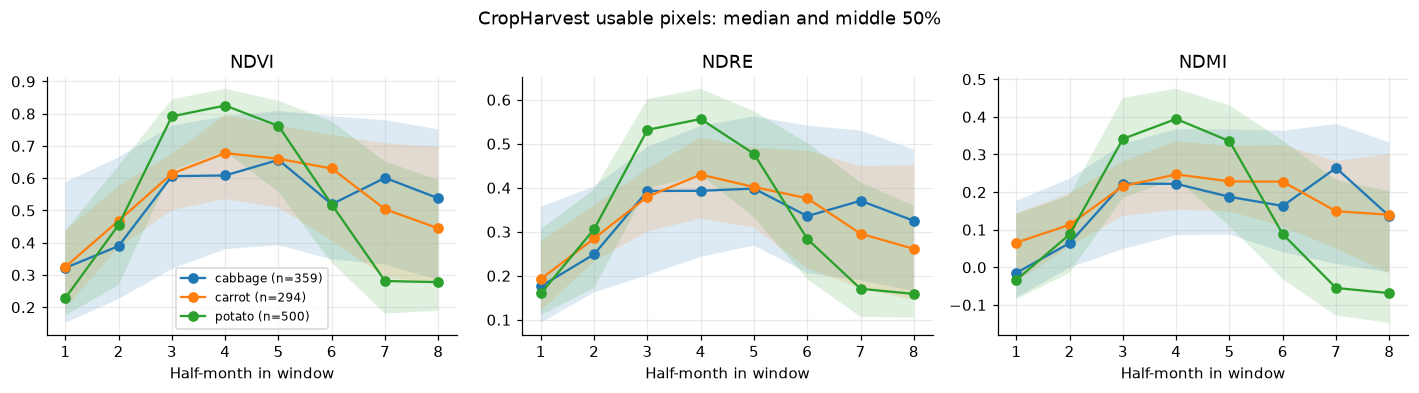

In [69]:
usable = pd.DataFrame(usable_rows)
if usable.empty:
    print("No usable CropHarvest pixels to plot.")
else:
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharex=True)
    for ax, index in zip(axes, ["NDVI", "NDRE", "NDMI"]):
        for crop in CROP_ORDER:
            rows = usable.loc[usable["crop"].eq(crop)]
            if rows.empty:
                continue
            values = rows[[f"bin_{b:02d}_{index}" for b in range(1, 9)]].astype(float)
            ax.plot(range(1, 9), values.median(), marker="o", label=f"{crop} (n={len(rows)})")
            ax.fill_between(range(1, 9), values.quantile(0.25), values.quantile(0.75), alpha=0.15)
        ax.set_title(index); ax.set_xlabel("Half-month in window"); ax.grid(alpha=0.25)
    axes[0].legend(fontsize=8)
    fig.suptitle("CropHarvest usable pixels: median and middle 50%")
    plt.tight_layout(); plt.show()

Usable pixels per country.

In [70]:
if not usable.empty:
    display(pd.crosstab(usable["partition_group"].str.split("|").str[1], usable["crop"])
            .reindex(columns=CROP_ORDER, fill_value=0).rename_axis("country"))

crop,cabbage,carrot,potato
country,,,
France,76,60,205
Madagascar,4,123,139
Martinique (FR),148,11,0
Réunion (FR),4,100,156
Senegal,127,0,0


**Result:** each crop comes from different places — cabbage mostly Martinique and Senegal, carrot Madagascar and Réunion, potato France, Réunion and Madagascar. Senegal has only cabbage; Martinique has no potato.

## 18. Known differences from FranceCrops and Sen4AgriNet

These come from the data itself and cannot be fixed by processing:

1. **Year:** CropHarvest usable pixels are from 2019 and 2021; FranceCrops is 2022, Sen4AgriNet 2020.
2. **Place:** CropHarvest is mostly Madagascar (southern hemisphere) plus France, Réunion, Martinique and Senegal; FranceCrops is France only.
3. **Label source:** CropHarvest mixes field surveys (JECAM, some filler dates) and farmer declarations; FranceCrops uses declarations only.
4. **Sample size:** cabbage and carrot fall short of 500 usable pixels, and no crop reaches the pipeline's 3,000-candidate minimum.
5. **Seasons crossing New Year:** these are logged but not downloaded (same as FranceCrops). This removes many Madagascar seasons that start in October.

Pixels picked vs. usable per crop.

In [71]:
differences = pd.DataFrame({
    "candidates_sampled": pd.Series(Counter(
        crop for inputs in year_inputs.values()
        for crop, n in inputs["summary"]["candidate_pixels_per_crop"].items()
        for _ in range(n))),
    "usable_pixels": pd.DataFrame(usable_summary).set_index("crop")["selected_usable_pixels"],
}).reindex(CROP_ORDER).fillna(0).astype(int)
differences["usable_target"] = usable_pixels_per_crop
differences["shortfall"] = (differences["usable_target"] - differences["usable_pixels"]).clip(lower=0)

Add the years, countries and cross-year seasons per crop, then save.

In [72]:
def values_in_group(crop, position):
    """Unique parts of partition_group (1 = country, 2 = year) for one crop."""
    if usable.empty:
        return ""
    groups_of_crop = usable.loc[usable["crop"].eq(crop), "partition_group"]
    return ", ".join(sorted({p.split("|")[position] for p in groups_of_crop}))

differences["years"] = [values_in_group(c, 2) for c in differences.index]
differences["countries"] = [values_in_group(c, 1) for c in differences.index]
differences["cross_year_field_groups"] = (gate.groupby("crop")["adjacent_year_needed"].sum()
                                          .reindex(CROP_ORDER).fillna(0).astype(int))
display(differences)

save_json(cropharvest_root / "known_differences.json", {
    "comparison": {"francecrops": {"year": 2022, "country": "France", "labels": "RPG declarations"},
                   "sen4agrinet": {"year": 2020}},
    "cropharvest": differences.reset_index().to_dict("records"),
})

,candidates_sampled,usable_pixels,usable_target,shortfall,years,countries,cross_year_field_groups
cabbage,2112,359,500,141,"2019, 2021","France, Madagascar, Martinique (FR), Réunion (FR), Senegal",6
carrot,1862,294,500,206,2019,"France, Madagascar, Martinique (FR), Réunion (FR)",18
potato,19779,500,500,0,2019,"France, Madagascar, Réunion (FR)",27


**Result:** shortfall to 500 — cabbage 141, carrot 206, potato 0. Cross-year seasons skipped: cabbage 6, carrot 18, potato 27 field groups.

# Summary

| Step | Cabbage | Carrot | Potato |
|---|---:|---:|---:|
| Clean labels (2019–2025) | 213 | 380 | 580 |
| Polygon fields | 176 | 380 | 577 |
| Interior pixels after 10 m buffer | 2,112 | 1,862 | 19,779 |
| Pixels passing the timing check | 475 | 805 | 1,434 |
| **Usable pixels (target 500)** | **359** | **294** | **500** |

**Findings**
- CropHarvest adds real cabbage, carrot and potato fields, but small ones: the 10 m buffer keeps only 517 of 1,133 fields.
- Clouds and timing are the biggest filter: only about 45% of field-days are clear, and many fields show no clear growing rise inside one year.
- Cabbage and carrot do not reach 500 usable pixels; potato does.
- Crop and country are tightly linked (e.g. Senegal = cabbage only), so any model result here must be checked per country.
- The two handoff files are ready: add them to notebook 03's `source_manifest_paths`.